# Predictive Memory Leak Detection — 02: Baseline forecasts

This stage trains statistical forecasting baselines and produces **measured MAE/RMSE and actual-versus-predicted charts**. It does not train an LSTM or claim leak-warning classification accuracy.

## Run in free Colab
1. Upload this notebook to Colab and keep the runtime on **CPU**.
2. Run the cells in order. The first cell installs the two required model/plotting packages if needed.
3. When prompted, upload **`review2_preprocessed_colab.zip`**, approximately 23 MB, saved from your successful preprocessing run. Do not upload the 214 MB raw ZIP here.
4. Review the tables, charts and final verification message.
5. Save the downloaded **`review2_baseline_results.zip`**. Keep a copy of this executed notebook too.

## Experiment fixed before results
- Four separate recordings and the existing chronological splits. Antarex forecasts **60 seconds ahead**; Westermo forecasts **five minutes ahead**.
- Persistence predicts the last observed memory value.
- Linear trend fits the last 12, 30 or 60 observations; its history length is selected on validation RMSE.
- ARIMA(p,1,0), without drift, tries p = 1, 3, 5. It uses statsmodels' Yule-Walker estimator on the longest contiguous training segment, without joining across gaps. Its order is selected on validation RMSE. This is a restricted initial ARIMA comparison, not an exhaustive Box-Jenkins analysis.
- All model choices are saved before scoring test forecasts. Coefficients are never refitted on validation/test values. At each new origin, the observed past through that origin is available; the future is not.
- Clip every model's prediction to [0,1]. Raw predictions and clipping counts are also saved.
- Error units are **percentage points of total RAM**, not accuracy percentages. Memory pressure is `1 - available/total`.
- The figures use intervals chosen by time/event rules, not by model performance. Overall scores include every eligible validation/test window. Overlapping windows are not independent trials.

The earlier multivariate features remain ready for LSTM. These first baselines use memory history only. Westermo remains unlabeled; Antarex's injected-leak intervals are context, not demonstrated warnings or exhaustion events.

## Methodological sources
Review 1 reference [3], [Assi et al. (2022)](https://doi.org/10.22075/ijnaa.2022.26974.3505), motivates the statistical-versus-LSTM comparison. None of its reported errors are reused. The implementation follows the primary [statsmodels ARIMA specification](https://www.statsmodels.org/v0.14.6/generated/statsmodels.tsa.arima.model.ARIMA.html), [estimator documentation](https://www.statsmodels.org/v0.14.6/generated/statsmodels.tsa.arima.model.ARIMA.fit.html) and [rolling-origin forecasting example](https://www.statsmodels.org/v0.12.2/examples/notebooks/generated/statespace_forecasting.html).


## 1. Prepare the runtime
A GPU is not used. NumPy and pandas from your environment are retained; their actual versions are recorded in the results.

In [1]:
import importlib.metadata
import importlib.util
from pathlib import Path
import subprocess
import sys

needed=[]
for package,version in [('statsmodels','0.14.6'),('matplotlib','3.10.8')]:
    try:
        current=importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        current=None
    if current!=version:
        needed.append(f'{package}=={version}')
if needed:
    subprocess.check_call([sys.executable,'-m','pip','install','--quiet',*needed])
print('Model and plotting dependencies are ready.')


Model and plotting dependencies are ready.


## 2. Upload the prepared data
The SHA-256 and per-file checks below ensure this is the verified Colab preprocessing output for the experiment.

In [2]:
try:
    IN_COLAB=importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:
    IN_COLAB=False
if IN_COLAB:
    WORK=Path('/content/memory_leak_baselines')
    INPUT_PACKAGE=Path('/content/review2_preprocessed_colab.zip')
    if not INPUT_PACKAGE.exists():
        from google.colab import files
        uploaded=files.upload()
        if 'review2_preprocessed_colab.zip' not in uploaded:
            raise FileNotFoundError('Upload review2_preprocessed_colab.zip and rerun this cell.')
        INPUT_PACKAGE.write_bytes(uploaded['review2_preprocessed_colab.zip'])
        del uploaded
else:
    WORK=Path.cwd().resolve()
    if not (WORK/'data/packages/review2_preprocessed_colab.zip').exists() and (WORK.parent/'data/packages/review2_preprocessed_colab.zip').exists():
        WORK=WORK.parent
    INPUT_PACKAGE=WORK/'data/packages/review2_preprocessed_colab.zip'
SOURCE=WORK/'data/baseline_inputs_colab'
OUTPUT=WORK/'results/baselines'
RESULT_PACKAGE=WORK/'data/packages/review2_baseline_results.zip'
print('Environment:', 'Colab' if IN_COLAB else 'local Python')
print('Input:', INPUT_PACKAGE)


Environment: local Python
Input: C:\dhruv\VIT\Sem-5\OS\Research_Project\data\packages\review2_preprocessed_colab.zip


## 3. Load the self-contained baseline implementation
The same source is also supplied as `src/baselines.py`. No other code upload is needed. Its seven focused tests include comparison against statsmodels forecasts and checks that changing future values cannot change a forecast or model selection.

In [3]:
"""Reproducible univariate baselines on the frozen Review 2 pilot splits."""
from __future__ import annotations

from datetime import datetime, timezone
import hashlib
import json
from pathlib import Path
import platform
import time
import warnings
import zipfile

import numpy as np
import pandas as pd
import scipy
import statsmodels
from statsmodels.tsa.arima.model import ARIMA
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

INPUT_SHA256 = '287ffaa139819f78f493e540e527c56ac0c240477034c76fa8b258b94d5e6bb2'
RAW_SHA256 = '06df79379df958405ab3d3486dea3e81dff2eb6fa26e53b4cf6ea634210db75e'
TREND_HISTORY = (12, 30, 60)
AR_ORDERS = (1, 3, 5)
MODELS = ('persistence', 'linear_trend', 'arima')
COLORS = {'actual':'#172B4D','persistence':'#00897B','linear_trend':'#C77800','arima':'#6C4AB6'}


def dump_json(path, data):
    Path(path).write_text(json.dumps(data, indent=2, allow_nan=False), encoding='utf-8')


def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        while chunk := stream.read(4*1024*1024):
            digest.update(chunk)
    return digest.hexdigest()


def unpack_inputs(package, destination):
    package, destination = Path(package), Path(destination).resolve()
    if sha256(package) != INPUT_SHA256:
        raise ValueError('Use the checked review2_preprocessed_colab.zip supplied for this experiment.')
    destination.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(package) as archive:
        manifest = json.loads(archive.read('MANIFEST.json'))
        if manifest['raw_package_sha256'] != RAW_SHA256:
            raise ValueError('Unexpected source data provenance')
        for item in manifest['files']:
            path = (destination/item['entry']).resolve()
            if not path.is_relative_to(destination):
                raise ValueError('Unsafe archive path')
            content = archive.read(item['entry'])
            if len(content) != item['bytes'] or hashlib.sha256(content).hexdigest() != item['sha256']:
                raise ValueError('Input content checksum failed: '+item['entry'])
            path.parent.mkdir(parents=True, exist_ok=True)
            path.write_bytes(content)
    return destination


def errors(actual, prediction):
    actual, prediction = np.asarray(actual), np.asarray(prediction)
    if actual.shape != prediction.shape or len(actual) == 0:
        raise ValueError('Nonempty paired forecasts are required')
    if not np.isfinite(actual).all() or not np.isfinite(prediction).all():
        raise ValueError('Nonfinite evaluation values')
    difference = prediction-actual
    mae, rmse = float(np.mean(np.abs(difference))), float(np.sqrt(np.mean(difference**2)))
    return {'n':len(actual),'mae_fraction':mae,'rmse_fraction':rmse,
            'mae_percentage_points':100*mae,'rmse_percentage_points':100*rmse}


def linear_forecast(y, origins, history_steps, horizon_steps):
    offsets = np.arange(history_steps)-history_steps+1
    past = np.asarray(y)[np.asarray(origins)[:,None]+offsets]
    centered = np.arange(history_steps)-(history_steps-1)/2
    slope = past @ (centered/np.sum(centered**2))
    return past.mean(axis=1)+slope*((history_steps-1)/2+horizon_steps)


def arima_forecast(y, origins, coefficients, horizon_steps):
    """Exact conditional mean for ARIMA(p,1,0), no drift, at each origin."""
    origins = np.asarray(origins, dtype=np.int64)
    coefficients = np.asarray(coefficients, dtype=np.float64)
    p = len(coefficients)
    lag_indices = origins[:,None]-np.arange(p)
    lag_differences = (np.asarray(y)[lag_indices]-np.asarray(y)[lag_indices-1]).copy()
    forecast = np.asarray(y)[origins].astype(np.float64, copy=True)
    for _ in range(horizon_steps):
        next_difference = lag_differences @ coefficients
        forecast += next_difference
        lag_differences[:,1:] = lag_differences[:,:-1].copy()
        lag_differences[:,0] = next_difference
    return forecast


def longest_training_segment(timestamps, valid, split, cadence):
    allowed = np.asarray(valid) & (np.asarray(split) == 0)
    starts = np.flatnonzero(allowed & np.r_[True, ~allowed[:-1] | (np.diff(timestamps) != cadence)])
    ends = np.flatnonzero(allowed & np.r_[~allowed[1:] | (np.diff(timestamps) != cadence), True])+1
    if not len(starts):
        raise ValueError('No contiguous training segment')
    lengths = ends-starts
    chosen = int(np.argmax(lengths))  # first segment wins a length tie
    if lengths[chosen] < 100:
        raise ValueError('Training segment is too short')
    return int(starts[chosen]), int(ends[chosen])


def fit_arima(y_train, p):
    started = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        fitted = ARIMA(np.asarray(y_train)*100, order=(p,1,0), trend='n',
                       enforce_stationarity=True).fit(method='yule_walker', cov_type='none', low_memory=True)
    coefficients = fitted.arparams.tolist()
    if not np.isfinite(coefficients).all() or not np.isfinite(fitted.params).all():
        raise ValueError('Nonfinite ARIMA fit')
    return {'order':[p,1,0],'trend':'n','estimator':'yule_walker',
            'coefficients':coefficients,'parameters_percentage_point_scale':dict(zip(fitted.param_names,fitted.params.tolist())),
            'fit_seconds':time.perf_counter()-started,'training_rows':len(y_train),
            'warnings':sorted(set(str(w.message) for w in caught))}


def validate_windows(arrays, windows, info):
    t, valid, split = arrays['timestamps'], arrays['valid'], arrays['split_code']
    h,o,z = (windows[c].to_numpy(dtype=np.int64) for c in ['history_start_index','origin_index','target_index'])
    assert h.min() >= 0 and z.max() < len(t)
    invalid_prefix = np.r_[0,np.cumsum(~valid)]
    assert (invalid_prefix[z+1]-invalid_prefix[h] == 0).all()
    assert (split[h] == split[z]).all()
    assert (split[o] == windows['split_code']).all()
    assert (t[z]-t[o] == info['forecast_horizon_seconds']).all()
    assert (t[z]-t[h] == (info['history_steps']-1+info['horizon_steps'])*info['cadence_seconds']).all()
    assert (o-h+1 == info['history_steps']).all()
    assert windows['origin_index'].is_unique
    return {'complete_windows_checked':len(windows),'passed':True}


def select_settings(y, windows, train_slice, horizon):
    """Fit on training only; this function evaluates validation origins only."""
    val = windows[windows['split'].eq('validation')]
    origins, targets = val['origin_index'].to_numpy(), val['target_index'].to_numpy()
    actual = y[targets]
    candidates, fits = [], {}
    for n in TREND_HISTORY:
        raw = linear_forecast(y,origins,n,horizon)
        candidates.append({'family':'linear_trend','setting':n,**errors(actual,np.clip(raw,0,1))})
    for p in AR_ORDERS:
        fits[str(p)] = fit_arima(y[train_slice],p)
        raw = arima_forecast(y,origins,fits[str(p)]['coefficients'],horizon)
        candidates.append({'family':'arima','setting':p,**errors(actual,np.clip(raw,0,1))})
    selected = {}
    for family in ['linear_trend','arima']:
        chosen = min((c for c in candidates if c['family']==family),key=lambda c:(c['rmse_fraction'],c['setting']))
        selected[family] = chosen['setting']
    return selected,candidates,fits


def evaluate_partition(y, arrays, windows, split_name, selected, fits, horizon):
    w = windows[windows['split'].eq(split_name)].copy()
    o,z = w['origin_index'].to_numpy(),w['target_index'].to_numpy()
    forecasts = {'persistence':y[o],
                 'linear_trend':linear_forecast(y,o,selected['linear_trend'],horizon),
                 'arima':arima_forecast(y,o,fits[str(selected['arima'])]['coefficients'],horizon)}
    frame = w[['origin_index','target_index','origin_timestamp','target_timestamp']].copy()
    frame['actual'] = y[z]
    frame['leak_active_at_origin'] = arrays['leak_active'][o]
    frame['leak_active_at_target'] = arrays['leak_active'][z]
    rows=[]
    for model, raw in forecasts.items():
        pred=np.clip(raw,0,1)
        frame[model+'_raw']=raw
        frame[model]=pred
        rows.append({'model':model,'split':split_name,**errors(y[z],pred),
                     'clipped_forecasts':int(((raw<0)|(raw>1)).sum())})
    return frame,rows


def save_figure(fig, path):
    fig.savefig(path.with_suffix('.png'),dpi=180,facecolor='white')
    fig.savefig(path.with_suffix('.pdf'),facecolor='white')
    plt.close(fig)


def plot_forecasts(frame, episodes, start, end, path, title, horizon_seconds):
    view=frame[frame['target_timestamp'].between(start,end)].copy()
    if view.empty:
        raise ValueError('Chosen illustrative interval has no forecasts')
    fig,ax=plt.subplots(figsize=(12,4.8),layout='constrained')
    x=(view['target_timestamp'].to_numpy()-start)/60
    ax.plot(x,view['actual']*100,label='Actual',color=COLORS['actual'],lw=2.1,zorder=5)
    for model,label,style in [('persistence','Persistence','--'),('linear_trend','Linear trend',':'),('arima','ARIMA','-.')]:
        ax.plot(x,view[model]*100,label=label,color=COLORS[model],lw=1.5,ls=style,alpha=.9)
    if episodes is not None:
        first=True
        for row in episodes.itertuples(index=False):
            if row.end>start and row.start<end:
                ax.axvspan((max(row.start,start)-start)/60,(min(row.end,end)-start)/60,
                           color='#E57373',alpha=.16,label='Injected leak active' if first else None)
                first=False
    ax.set(title=title,xlabel='Target time: minutes from interval start',ylabel='Memory pressure (% of total RAM)')
    ax.grid(alpha=.18)
    ax.spines[['top','right']].set_visible(False)
    ax.legend(loc='upper left',ncols=3,fontsize=9)
    fig.supxlabel(f'{horizon_seconds}-second-ahead rolling forecasts shown at target times; interval start = {int(start)}',fontsize=9)
    save_figure(fig,path)
    view.to_csv(path.with_suffix('.csv'),index=False)
    return {'file':path.name,'start_timestamp':int(start),'end_timestamp':int(end),'plotted_rows':len(view)}


def plot_error_comparison(metrics, path):
    test=metrics[metrics['split'].eq('test')]
    datasets=test['dataset'].drop_duplicates().tolist()
    fig,axes=plt.subplots(2,2,figsize=(12,8),layout='constrained')
    for ax,name in zip(axes.flat,datasets):
        d=test[test['dataset'].eq(name)].set_index('model')
        pos=np.arange(2)
        for j,model in enumerate(MODELS):
            values=d.loc[model,['mae_percentage_points','rmse_percentage_points']].to_numpy(dtype=float)
            bars=ax.bar(pos+(j-1)*.24,values,width=.23,color=COLORS[model],label=model.replace('_',' ').title())
            ax.bar_label(bars,fmt='%.3f',fontsize=8,padding=3)
        ax.set_xticks(pos,['MAE','RMSE'])
        ax.set_title(name.replace('_',' ').title())
        ax.set_ylabel('Error (percentage points of total RAM)')
        ax.set_ylim(0,ax.get_ylim()[1]*1.17)
        ax.grid(axis='y',alpha=.18)
        ax.spines[['top','right']].set_visible(False)
    axes[0,0].legend(fontsize=8)
    fig.suptitle('Held-out forecast errors | same origins and horizon within each recording',fontsize=14)
    save_figure(fig,path)


def run_experiment(source, output):
    source,output=Path(source),Path(output)
    output.mkdir(parents=True,exist_ok=True)
    pre=json.loads((source/'preprocessing_summary.json').read_text())
    started=time.perf_counter()
    all_metrics,records,figure_index=[],[],[]
    # Freeze every dataset's chosen settings before any test predictions are scored.
    loaded=[]
    for info in pre['datasets']:
        name=info['dataset']
        dest=output/name
        dest.mkdir(exist_ok=True)
        with np.load(source/name/'model_arrays.npz',allow_pickle=False) as archive:
            arrays={k:archive[k] for k in ['target_memory_pressure','timestamps','valid','split_code','leak_active']}
        y=arrays['target_memory_pressure'].astype(np.float64)
        windows=pd.read_csv(source/name/'forecast_windows.csv.gz')
        check=validate_windows(arrays,windows,info)
        a,b=longest_training_segment(arrays['timestamps'],arrays['valid'],arrays['split_code'],info['cadence_seconds'])
        print('Fitting training-only candidates:',name,flush=True)
        selected,candidates,fits=select_settings(y,windows,slice(a,b),info['horizon_steps'])
        val,val_metrics=evaluate_partition(y,arrays,windows,'validation',selected,fits,info['horizon_steps'])
        winner=min(val_metrics,key=lambda r:(r['rmse_fraction'],MODELS.index(r['model'])))['model']
        frozen={'dataset':name,'selected_settings':selected,'best_family_by_validation_rmse':winner,
                'training_segment':{'start_index':a,'end_index_exclusive':b,'rows':b-a,
                                    'first_timestamp':int(arrays['timestamps'][a]),'last_timestamp':int(arrays['timestamps'][b-1])},
                'fits':fits,'input_checks':check,'selection_partition':'validation','fit_partition':'train',
                'test_used_for_selection':False}
        dump_json(dest/'frozen_settings.json',frozen)
        pd.DataFrame(candidates).to_csv(dest/'validation_candidates.csv',index=False)
        val.to_csv(dest/'validation_predictions.csv.gz',index=False,compression='gzip')
        for row in val_metrics: row['dataset']=name
        all_metrics.extend(val_metrics)
        loaded.append((info,arrays,y,windows,frozen))
    dump_json(output/'selection_freeze.json',{'completed_utc':datetime.now(timezone.utc).isoformat(),
              'input_sha256':INPUT_SHA256,'settings_files':{d[0]['dataset']:sha256(output/d[0]['dataset']/'frozen_settings.json') for d in loaded},
              'test_evaluation_started':False})
    for info,arrays,y,windows,frozen in loaded:
        name=info['dataset']; dest=output/name
        print('Evaluating frozen baselines on test:',name,flush=True)
        before=time.perf_counter()
        test,test_metrics=evaluate_partition(y,arrays,windows,'test',frozen['selected_settings'],frozen['fits'],info['horizon_steps'])
        elapsed=time.perf_counter()-before
        test.to_csv(dest/'test_predictions.csv.gz',index=False,compression='gzip')
        for row in test_metrics: row['dataset']=name
        all_metrics.extend(test_metrics)
        episodes=pd.read_csv(source/name/'leak_episodes.csv') if name.startswith('antarex') else None
        if episodes is not None:
            strata=[]
            for state,label in [(1,'leak_active_at_origin'),(0,'no_leak_active_at_origin_including_other_faults')]:
                sub=test[test['leak_active_at_origin'].eq(state)]
                if len(sub):
                    for model in MODELS: strata.append({'group':label,'model':model,**errors(sub['actual'],sub[model])})
            pd.DataFrame(strata).to_csv(dest/'test_forecast_errors_by_leak_state.csv',index=False)
            first=int(test['target_timestamp'].min())
            figure_index.append(plot_forecasts(test,episodes,first,first+1800,dest/'first_test_30min',
                                               'Antarex | first 30 minutes of eligible test forecasts',info['forecast_horizon_seconds']))
            candidates=episodes[(episodes['start']>=test['origin_timestamp'].min()+600)&(episodes['start']<=test['target_timestamp'].max()-1200)]
            if len(candidates):
                event=candidates.iloc[0]
                figure_index.append(plot_forecasts(test,episodes,int(event['start'])-600,int(event['start'])+1200,
                                                   dest/'first_test_leak','Antarex | first eligible test leak episode',info['forecast_horizon_seconds']))
        elif name=='westermo_1':
            first=int(test['target_timestamp'].min())
            figure_index.append(plot_forecasts(test,None,first,first+86400,dest/'first_test_day',
                                               'Westermo 1 | first day of eligible test forecasts',info['forecast_horizon_seconds']))
        records.append({'dataset':name,'forecast_horizon_seconds':info['forecast_horizon_seconds'],
                        'selected_settings':frozen['selected_settings'],'best_family_by_validation_rmse':frozen['best_family_by_validation_rmse'],
                        'test_forecasts_per_model':len(test),'evaluation_seconds_including_metrics':elapsed})
    metrics=pd.DataFrame(all_metrics)
    metrics.to_csv(output/'metrics.csv',index=False)
    plot_error_comparison(metrics,output/'test_error_comparison')
    result={'stage':'baseline forecasting','input_package_sha256':INPUT_SHA256,
            'completed_utc':datetime.now(timezone.utc).isoformat(),'runtime':{'python':platform.python_version(),
            'numpy':np.__version__,'pandas':pd.__version__,'scipy':scipy.__version__,
            'statsmodels':statsmodels.__version__,'matplotlib':matplotlib.__version__},
            'elapsed_seconds':time.perf_counter()-started,'datasets':records,'figures':figure_index,
            'forecast_clip_range':[0,1],'classification_metrics_computed':False,'lstm_trained':False,
            'limitations':['Restricted ARIMA(p,1,0) search, no drift or MA terms.','No uncertainty or significance claim from overlapping windows.',
                          'Antarex does not reach memory exhaustion.','Westermo has no confirmed leak labels.',
                          'Local runtime measurements are not monitoring overhead or a Colab benchmark.']}
    dump_json(output/'experiment_summary.json',result)
    print(metrics[metrics['split'].eq('test')][['dataset','model','n','mae_percentage_points','rmse_percentage_points']].to_string(index=False),flush=True)
    return result


def verify_results(output):
    output=Path(output)
    summary=json.loads((output/'experiment_summary.json').read_text())
    freeze=json.loads((output/'selection_freeze.json').read_text())
    metrics=pd.read_csv(output/'metrics.csv')
    checked=0
    for info in summary['datasets']:
        name=info['dataset']
        assert sha256(output/name/'frozen_settings.json') == freeze['settings_files'][name]
        for split in ['validation','test']:
            pred=pd.read_csv(output/name/(split+'_predictions.csv.gz'))
            assert pred['origin_index'].is_unique
            assert (pred['target_timestamp']-pred['origin_timestamp'] == info['forecast_horizon_seconds']).all()
            for model in MODELS:
                measured=errors(pred['actual'],pred[model])
                saved=metrics[(metrics['dataset']==name)&(metrics['split']==split)&(metrics['model']==model)].iloc[0]
                for key in ['mae_fraction','rmse_fraction']:
                    assert np.isclose(measured[key],saved[key],rtol=1e-10,atol=1e-13)
                assert pred[model].between(0,1).all()
                assert len(pred)==saved['n']
                checked+=len(pred)
    receipt={'saved_forecast_values_checked':checked,'metrics_recomputed_from_saved_predictions':True,
             'selection_settings_unchanged':True,'all_checks_passed':True}
    dump_json(output/'result_integrity_checks.json',receipt)
    return receipt


def package_results(output, package):
    output,package=Path(output),Path(package)
    files=sorted(p for p in output.rglob('*') if p.is_file())
    manifest={'stage':'baseline forecasting','input_package_sha256':INPUT_SHA256,
              'files':[{'entry':p.relative_to(output).as_posix(),'sha256':sha256(p),'bytes':p.stat().st_size} for p in files]}
    package.parent.mkdir(parents=True,exist_ok=True)
    with zipfile.ZipFile(package,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as archive:
        for p in files: archive.write(p,p.relative_to(output).as_posix())
        archive.writestr('MANIFEST.json',json.dumps(manifest,indent=2))
    with zipfile.ZipFile(package) as archive:
        for item in manifest['files']:
            assert hashlib.sha256(archive.read(item['entry'])).hexdigest()==item['sha256']
    receipt={'file':package.name,'bytes':package.stat().st_size,'sha256':sha256(package),'every_entry_verified':True}
    dump_json(package.with_suffix('.manifest.json'),receipt)
    return receipt


## 4. Verify inputs, fit candidates, freeze settings and evaluate
All four datasets complete validation-based selection before any test scores are calculated. If a fit or data assertion fails, the experiment stops rather than silently dropping a model.

In [4]:
source_folder=unpack_inputs(INPUT_PACKAGE,SOURCE)
summary=run_experiment(source_folder,OUTPUT)
print('Runtime versions:',summary['runtime'])
print('LSTM trained:',summary['lstm_trained'])


Fitting training-only candidates: antarex_mono
Fitting training-only candidates: westermo_1
Fitting training-only candidates: westermo_2
Fitting training-only candidates: westermo_3
Evaluating frozen baselines on test: antarex_mono
Evaluating frozen baselines on test: westermo_1
Evaluating frozen baselines on test: westermo_2
Evaluating frozen baselines on test: westermo_3
     dataset        model     n  mae_percentage_points  rmse_percentage_points
antarex_mono  persistence 31032               0.361399                1.516596
antarex_mono linear_trend 31032               0.377387                1.743690
antarex_mono        arima 31032               0.362521                1.516401
  westermo_1  persistence 12891               0.094208                0.363477
  westermo_1 linear_trend 12891               0.145035                0.375828
  westermo_1        arima 12891               0.092984                0.317915
  westermo_2  persistence 12745               0.108831                0

## 5. Inspect measured test errors and frozen choices
Lower MAE/RMSE is better. A 1.0 percentage-point error means a difference equal to 1% of the machine's total RAM, not a 99% classification accuracy. The best family below was chosen by validation RMSE, even if another family happens to score better on test.

In [5]:
metrics=pd.read_csv(OUTPUT/'metrics.csv')
display(metrics[metrics['split'].eq('test')][['dataset','model','n','mae_percentage_points','rmse_percentage_points','clipped_forecasts']])
display(pd.DataFrame([{'dataset':d['dataset'],'trend_history_steps':d['selected_settings']['linear_trend'],
                      'ARIMA_order':str((d['selected_settings']['arima'],1,0)),
                      'best_family_by_validation':d['best_family_by_validation_rmse']} for d in summary['datasets']]))


dataset,model,n,mae_percentage_points,rmse_percentage_points,clipped_forecasts
antarex_mono,persistence,31032,0.361399,1.516596,0
antarex_mono,linear_trend,31032,0.377387,1.743690,595
antarex_mono,arima,31032,0.362521,1.516401,0
westermo_1,persistence,12891,0.094208,0.363477,0
westermo_1,linear_trend,12891,0.145035,0.375828,0
westermo_1,arima,12891,0.092984,0.317915,0
westermo_2,persistence,12745,0.108831,0.316791,0
westermo_2,linear_trend,12745,0.143653,0.348487,0
westermo_2,arima,12745,0.104707,0.291166,0
westermo_3,persistence,12891,0.240245,0.715420,0


dataset,trend_history_steps,ARIMA_order,best_family_by_validation
antarex_mono,12,"(3, 1, 0)",arima
westermo_1,60,"(5, 1, 0)",arima
westermo_2,30,"(5, 1, 0)",arima
westermo_3,30,"(5, 1, 0)",arima


## 6. Inspect the real forecast charts
Predictions are plotted at their future **target times**. Shading identifies recorded injected-leak intervals; it is not a predicted warning. The first eligible test leak is selected by timestamp, not by whichever example makes a model look best.

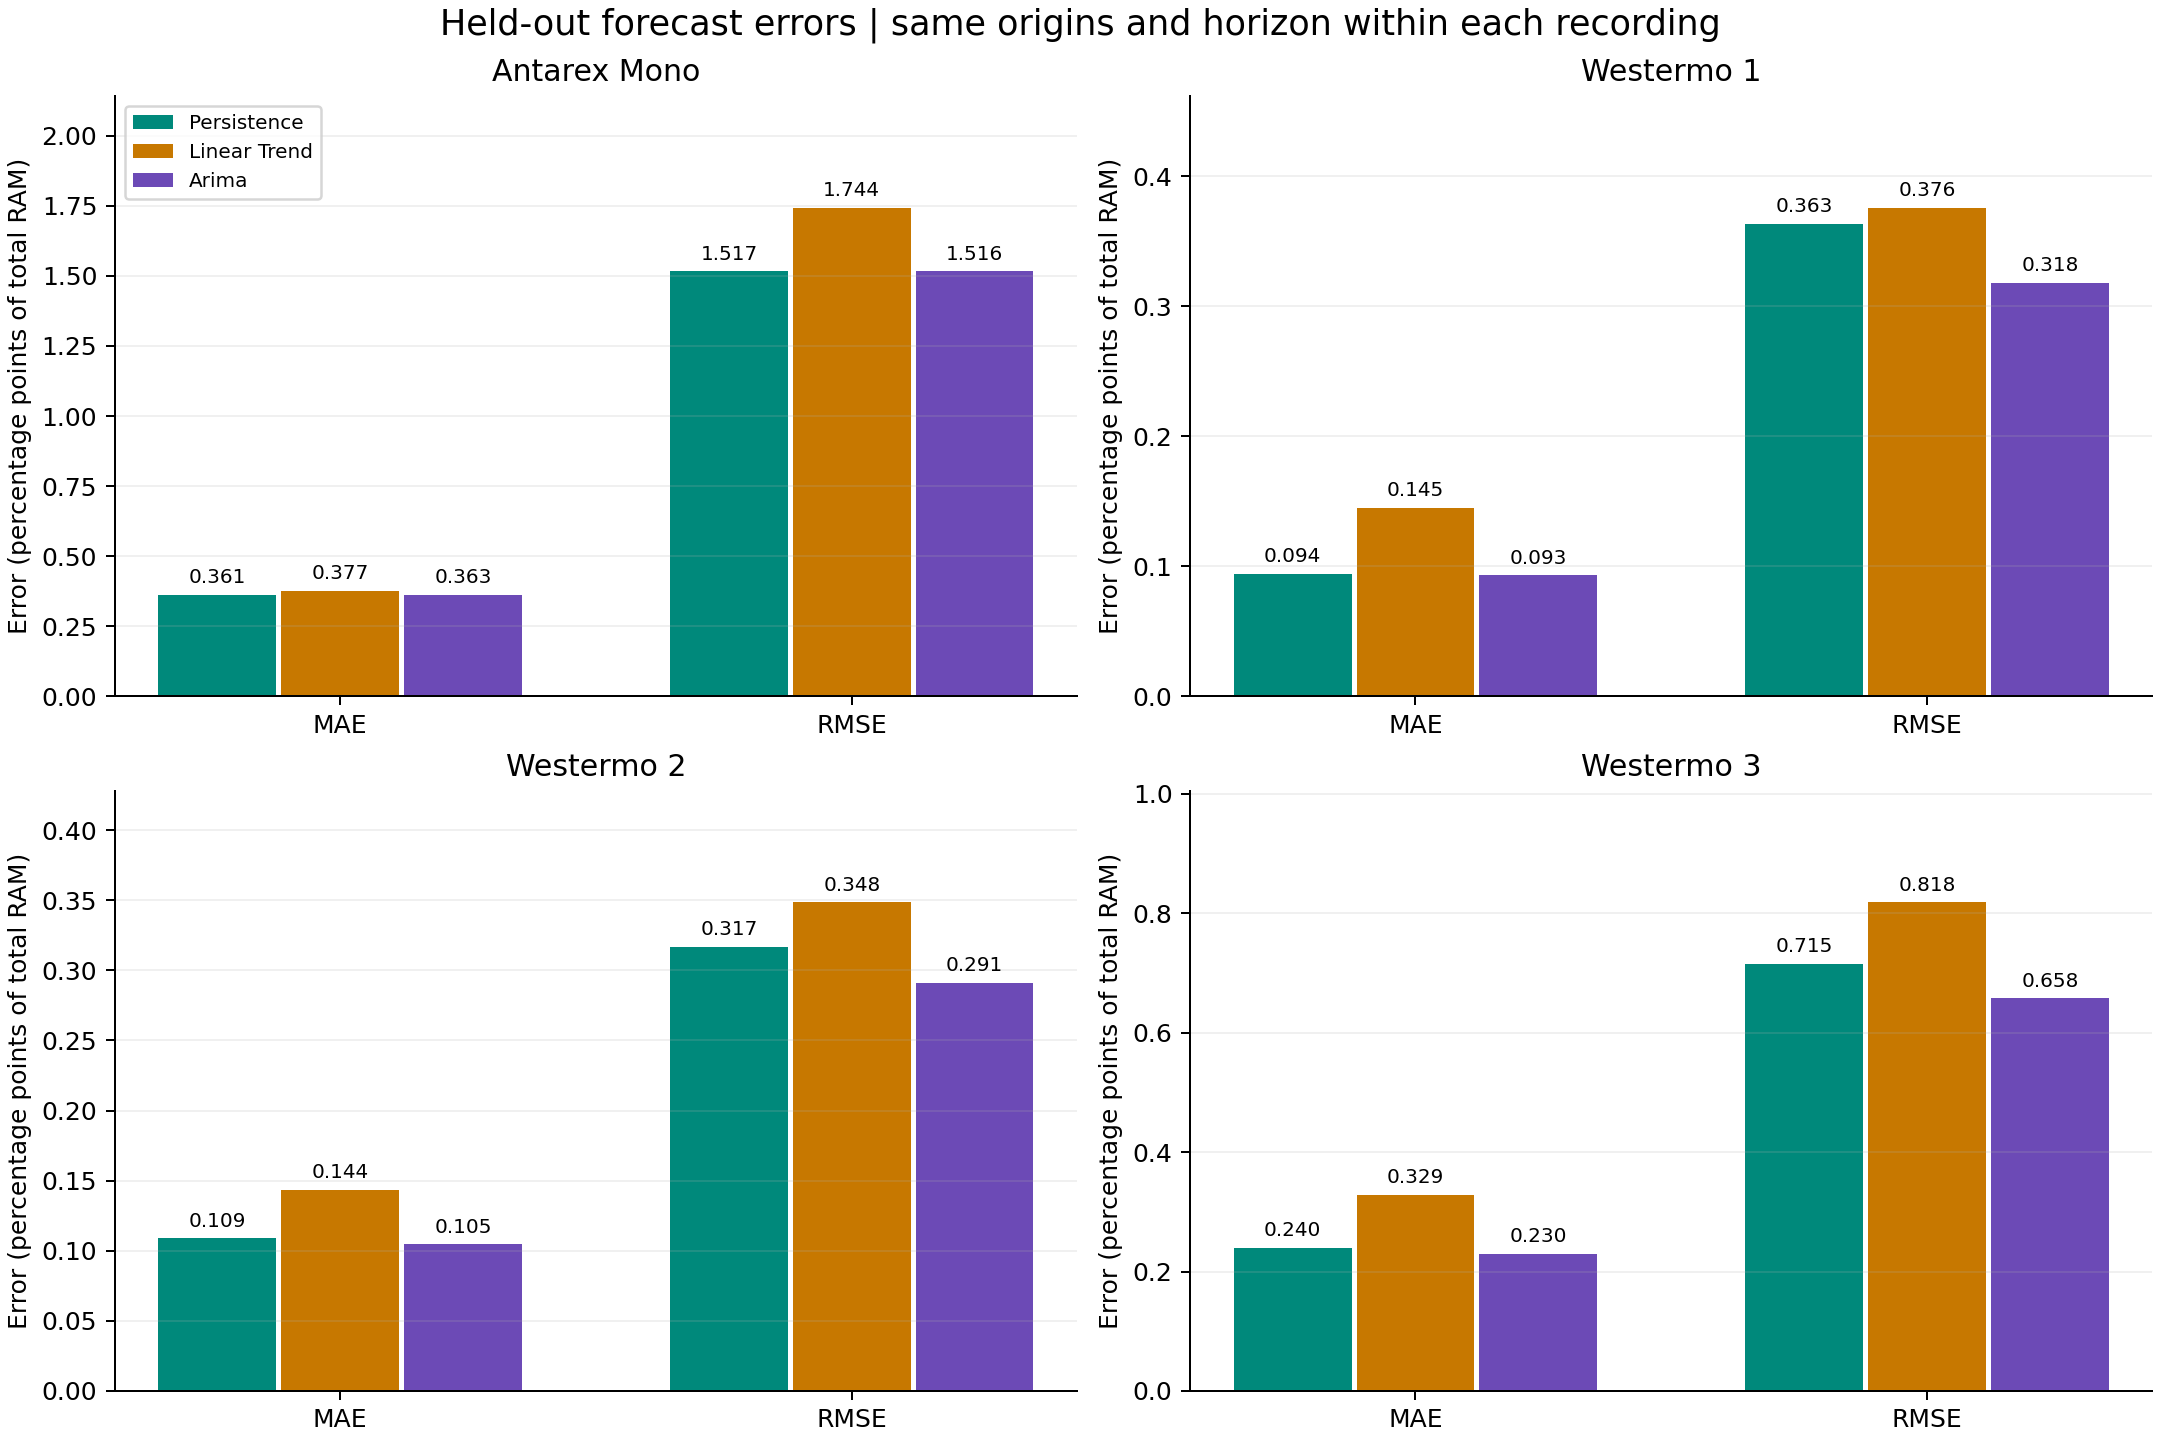

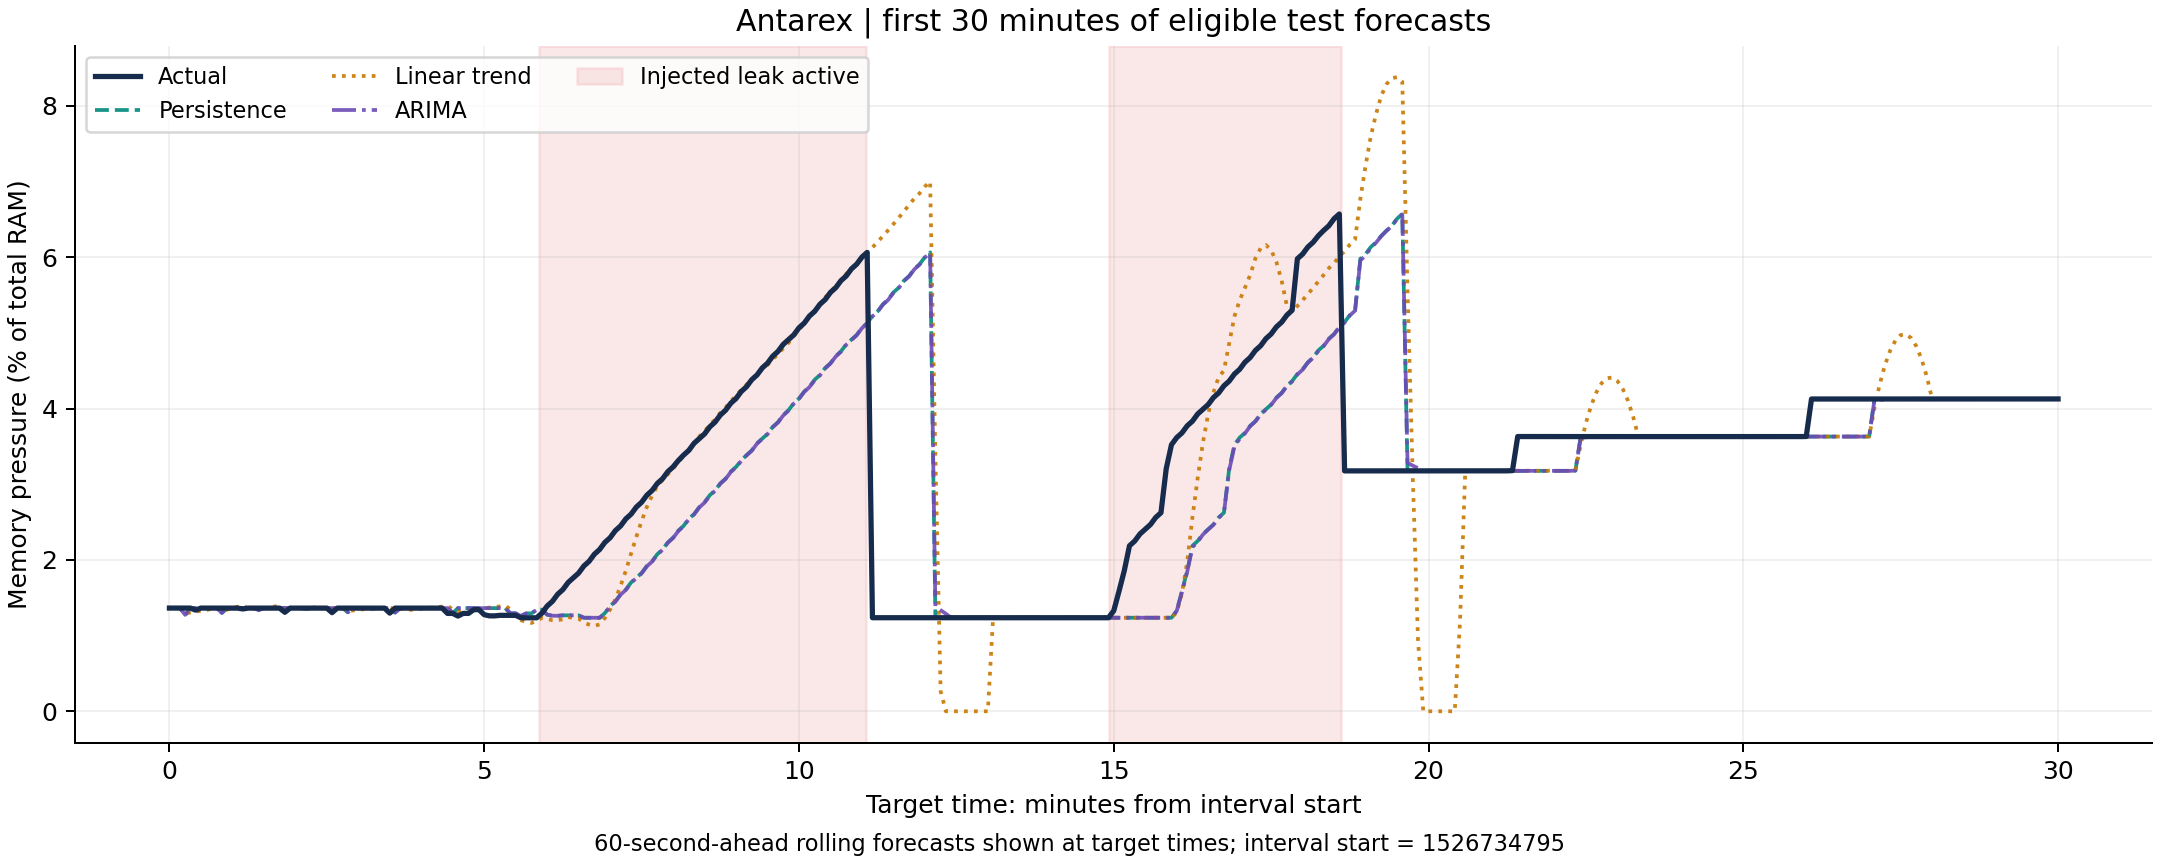

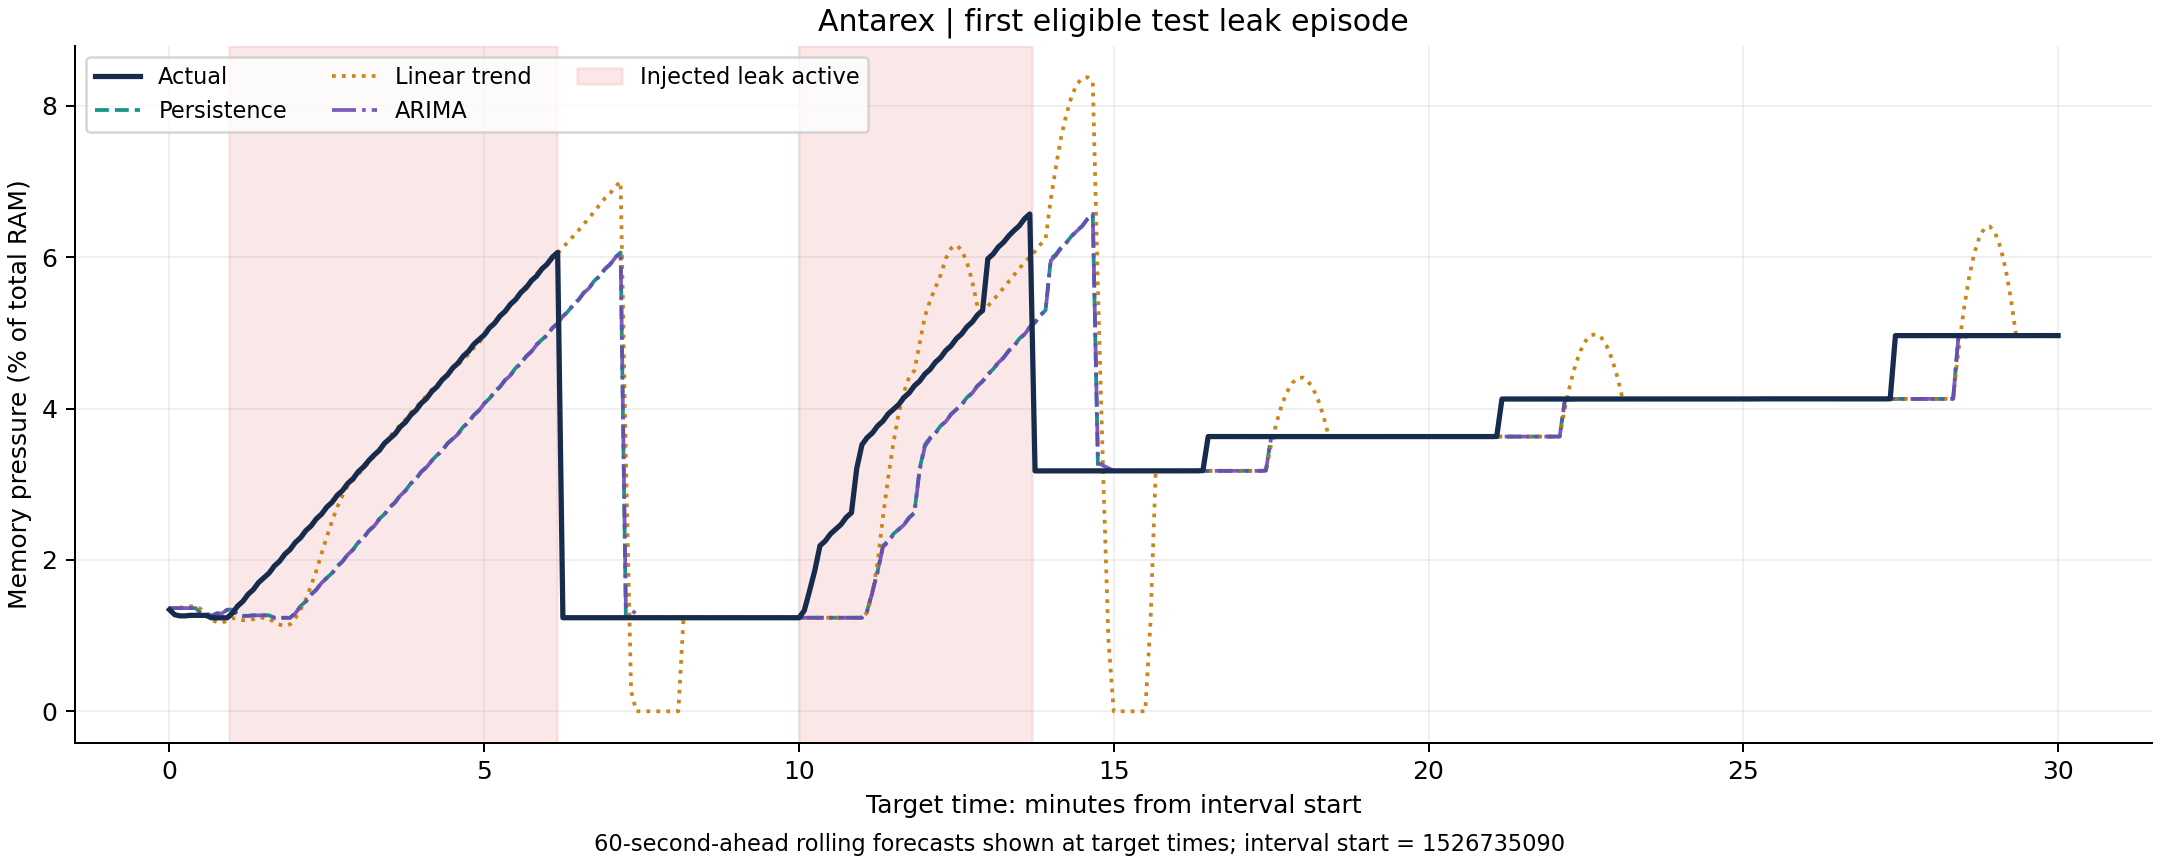

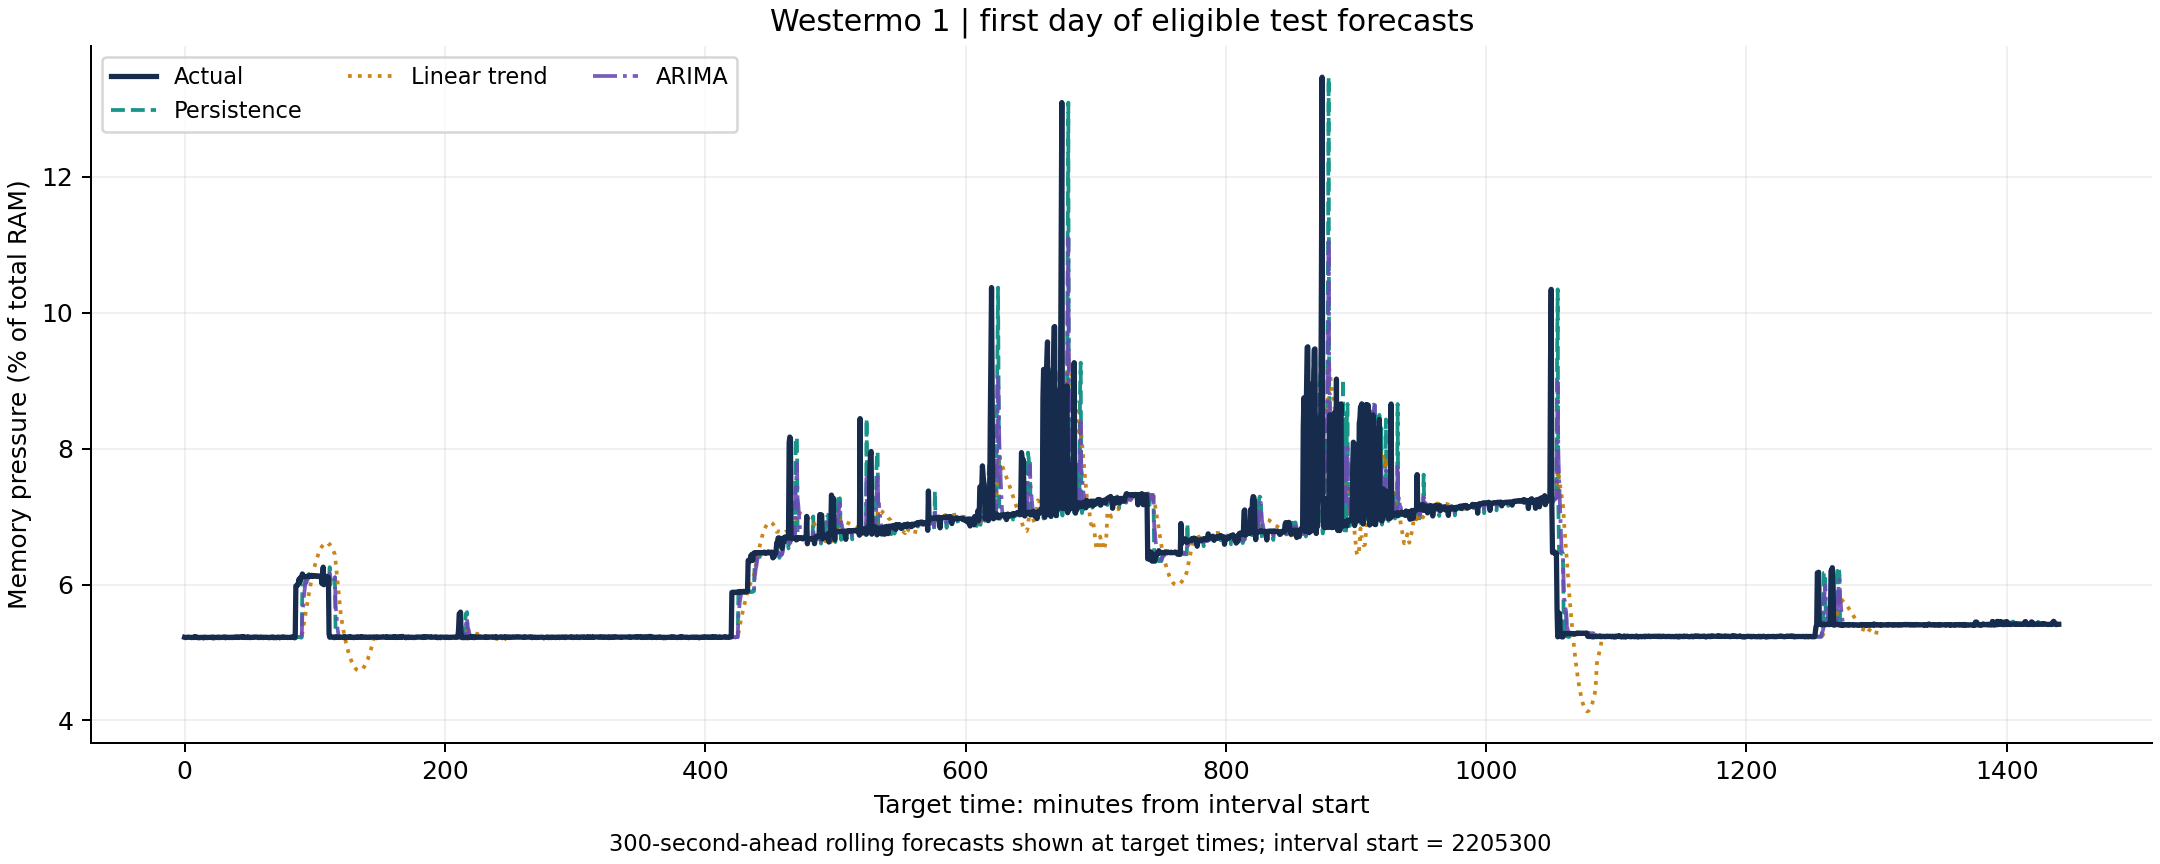

In [6]:
from PIL import Image
for relative in ['test_error_comparison.png','antarex_mono/first_test_30min.png',
                 'antarex_mono/first_test_leak.png','westermo_1/first_test_day.png']:
    figure=OUTPUT/relative
    if figure.exists():
        with Image.open(figure) as picture:
            display(picture)


## 7. Verify the saved forecasts and download the evidence
This recomputes errors from saved predictions and verifies that the selected settings have not changed. The ZIP includes prediction tables, parameters, validation candidates, measured errors, PNG/PDF figures and a hash manifest.

In [7]:
checks=verify_results(OUTPUT)
print(checks)
receipt=package_results(OUTPUT,RESULT_PACKAGE)
print(receipt)
if IN_COLAB:
    from google.colab import files
    files.download(str(RESULT_PACKAGE))


{'saved_forecast_values_checked': 417792, 'metrics_recomputed_from_saved_predictions': True, 'selection_settings_unchanged': True, 'all_checks_passed': True}
{'file': 'review2_baseline_results.zip', 'bytes': 6163649, 'sha256': '66f98d9dcbf05b4724817837c8b7511ba50b42ae2cb5f8663cb40b24001c5d24', 'every_entry_verified': True}


## Checkpoint and limitations
You now have a trained statistical baseline and demonstrable forecasting results. Small multivariate LSTM training, leak-warning evaluation and the supported research-paper draft remain later steps. Do not change subsequent model settings in response to these test scores; use the training/validation partitions.

The Antarex pilot contains controlled injections but no observed 80% memory-pressure crossing, so these results do not demonstrate warning lead time before exhaustion. Westermo cannot supply leak precision/recall. No Mann-Kendall significance test, hybrid model, deployment-overhead claim or final paper conclusion is produced in this stage.
